# Áreas e concentração operacional

**Tabela:** `dim_area` · **Grão:** Versão diária de uma área.

Análise descritiva do snapshot CSV. Figuras em azul, sem grade de fundo; PNG e SVG são exportados em `ml/reports/figures/eda/`. As relações usam as chaves vinculadas às versões do cadastro.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


In [2]:
from ml.eda import overview, profile, analyze_table
tables = load_tables()
df = tables["dim_area"]
overview("dim_area", df)


## Estrutura e qualidade

Confira nulos e cardinalidade. `vigencia_fim` vazia é esperada em versões atuais; prazo médio vazio é esperado em parceiros sem histórico. Colunas constantes não devem ser interpretadas como evidência preditiva.

In [3]:
display(style_table(profile(df)))

Coluna,Tipo,Nulos,Nulos (%),Distintos
id_area_raw,object,0,0.000000,20
id_area_natural,object,0,0.000000,20
nome_area,object,0,0.000000,20
gestor_responsavel,object,0,0.000000,20
email_gestor,object,0,0.000000,20
source_system,object,0,0.000000,1
codigo_area,object,0,0.000000,20
area_sk,int64,0,0.000000,20
vigencia_inicio,object,0,0.000000,1
vigencia_fim,float64,20,100.000000,0


## Distribuições e comportamento

As unidades e regras de agregação aparecem em cada figura. Valores financeiros descrevem o dataset sintético em BRL.

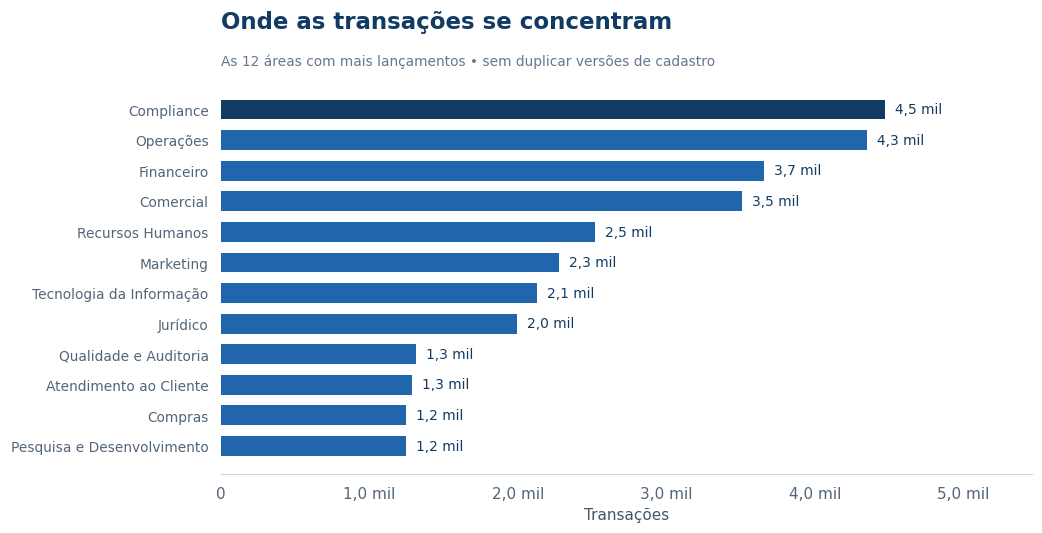

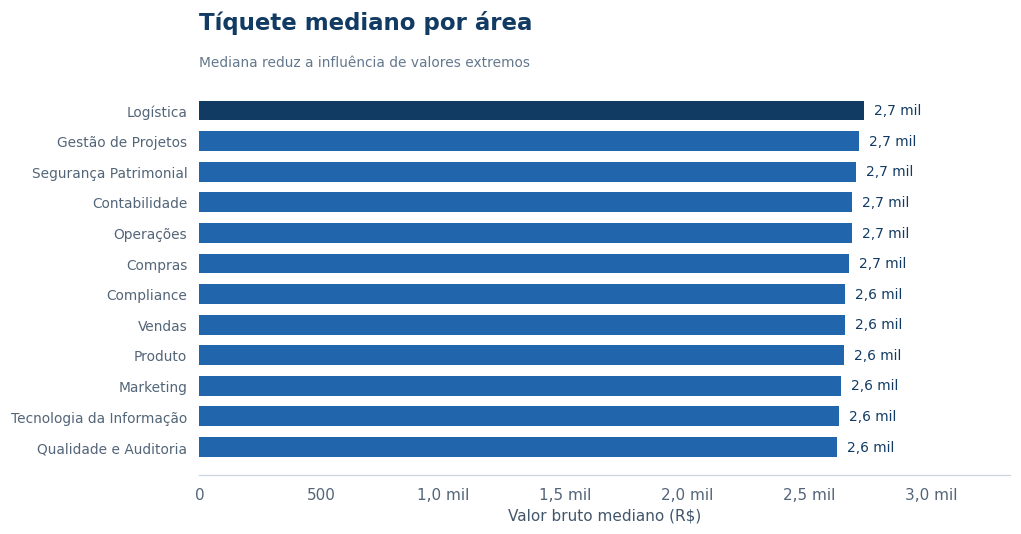

In [4]:
figures, notes = analyze_table("dim_area", tables)
for figure in figures:
    display(figure)
    plt.close(figure)


## Conclusões da tabela

In [5]:
display(Markdown("\n\n".join("- " + note for note in notes)))

- A área mais ativa reúne **11.2%** das transações; o volume não se distribui igualmente entre áreas.

- Área descreve a origem do lançamento; não identifica fraude. Use a chave da versão vinculada ao fato.

## Relação com o modelo

A detecção usa somente atributos conhecidos no lançamento e históricos de dias anteriores. Esta análise é descritiva; tabelas de liquidação, saldos, RH e ratings completos não entram automaticamente no treinamento.